---
## 0. Imports and Setup

In [14]:
import os, time, csv, warnings
warnings.filterwarnings('ignore')

# ── Output directories ────────────────────────────────────────────────────────
for d in ['../figures/circuits', '../figures/benchmarks', '../figures/slides', '../results']:
    os.makedirs(d, exist_ok=True)

# ── Qiskit 2.x ────────────────────────────────────────────────────────────────
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector, state_fidelity
import qiskit, qiskit_aer

# ── PennyLane ─────────────────────────────────────────────────────────────────
import pennylane as qml

# ── Scientific / plotting ─────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120


def get_counts(result_item):
    """
    Extract counts from a StatevectorSampler result regardless of classical
    register name.  QuantumCircuit(n, n) names the register 'c' by default,
    not 'meas', so hard-coding .data.meas raises AttributeError.
    This helper reads the actual register name dynamically.
    """
    data      = result_item.data
    creg_name = list(vars(data).keys())[0]
    return getattr(data, creg_name).get_counts()


print(f"Qiskit    : {qiskit.__version__}")
print(f"Aer       : {qiskit_aer.__version__}")
print(f"PennyLane : {qml.__version__}")
print("Setup complete.")

Qiskit    : 2.5.0
Aer       : 0.17.2
PennyLane : 0.45.0
Setup complete.


---
## 1. Helper Functions

In [15]:
def optimal_iterations(n_qubits: int, k: int = 1) -> int:
    """
    Optimal number of Grover iterations.
    r = floor( (pi/4) * sqrt(N/k) )  where N = 2^n
    """
    N = 2 ** n_qubits
    return max(1, int(np.floor((np.pi / 4) * np.sqrt(N / k))))


def theoretical_success_prob(n_qubits: int, iterations: int, k: int = 1) -> float:
    """
    Theoretical probability of measuring a marked item after `iterations` steps.
    P = sin^2( (2r+1) * arcsin(sqrt(k/N)) )
    """
    N     = 2 ** n_qubits
    theta = np.arcsin(np.sqrt(k / N))
    return float(np.sin((2 * iterations + 1) * theta) ** 2)


# Quick sanity check
for n in [2, 3, 4, 5]:
    r   = optimal_iterations(n)
    p   = theoretical_success_prob(n, r)
    N   = 2**n
    print(f"n={n}  N={N:3d}  optimal_r={r:2d}  P(success)={p:.4f}")

n=2  N=  4  optimal_r= 1  P(success)=1.0000
n=3  N=  8  optimal_r= 2  P(success)=0.9453
n=4  N= 16  optimal_r= 3  P(success)=0.9613
n=5  N= 32  optimal_r= 4  P(success)=0.9992


---
## 2. Grover's Algorithm — Qiskit 2.x

### 2a. Phase Oracle
The phase oracle for a single marked bitstring flips the phase of that state using an $n$-qubit controlled-Z gate. We implement it by:
1. Flipping qubits where the target bitstring has `0` (so the marked state maps to all-`1`s)
2. Applying a multi-controlled-Z (MCZ) gate
3. Unflipping the same qubits

In [16]:
def phase_oracle(n: int, marked: int) -> QuantumCircuit:
    """
    Phase oracle for a single marked item.
    Marks state |marked⟩ with a -1 phase flip.

    Implementation:
      - X gates on qubits where marked bitstring is 0
      - Multi-controlled-Z (= H on target + MCX + H on target)
      - X gates again to uncompute

    Parameters
    ----------
    n      : number of qubits
    marked : integer index of the marked state (0 <= marked < 2^n)
    """
    qc = QuantumCircuit(n, name=f'Oracle({marked:0{n}b})')
    # Bitstring of the marked item (little-endian for Qiskit)
    bitstring = format(marked, f'0{n}b')[::-1]   # reverse for Qiskit qubit ordering

    # Step 1: flip 0-bits so marked state becomes |11...1⟩
    for i, bit in enumerate(bitstring):
        if bit == '0':
            qc.x(i)

    # Step 2: multi-controlled-Z via H + MCX + H on last qubit
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)   # multi-controlled-X
    qc.h(n - 1)

    # Step 3: undo flips
    for i, bit in enumerate(bitstring):
        if bit == '0':
            qc.x(i)

    return qc


# Test: 3-qubit oracle for marked item 5 (|101⟩)
oracle_test = phase_oracle(3, 5)
print(oracle_test.draw('text'))
print(f"\nOracle for |101⟩: depth={oracle_test.depth()}, gates={dict(oracle_test.count_ops())}")

                    
q_0: ───────■───────
     ┌───┐  │  ┌───┐
q_1: ┤ X ├──■──┤ X ├
     ├───┤┌─┴─┐├───┤
q_2: ┤ H ├┤ X ├┤ H ├
     └───┘└───┘└───┘

Oracle for |101⟩: depth=3, gates={'x': 2, 'h': 2, 'ccx': 1}


### 2b. Diffusion Operator
The diffusion operator $D = 2|s\rangle\langle s| - I$ amplifies the marked state's amplitude. Implemented as:
$$D = H^{\otimes n} \cdot (2|0\rangle\langle 0| - I) \cdot H^{\otimes n}$$
where $(2|0\rangle\langle 0| - I)$ is a phase flip of every state *except* $|0\rangle$.

In [17]:
def diffusion_operator(n: int) -> QuantumCircuit:
    """
    Grover diffusion operator: D = H^n (2|0><0| - I) H^n
    Amplifies the amplitude of the marked state.
    """
    qc = QuantumCircuit(n, name='Diffusion')

    # H^n
    qc.h(range(n))
    # X^n  (maps |0⟩ → |1⟩ so MCZ targets all-ones state)
    qc.x(range(n))
    # Multi-controlled-Z (phase flip of |11...1⟩ = phase flip of |00...0⟩ after X)
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)
    # X^n (undo)
    qc.x(range(n))
    # H^n
    qc.h(range(n))

    return qc


diff_test = diffusion_operator(3)
print(diff_test.draw('text'))
print(f"\nDiffusion operator: depth={diff_test.depth()}, gates={dict(diff_test.count_ops())}")

     ┌───┐┌───┐          ┌───┐┌───┐     
q_0: ┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────
     ├───┤├───┤       │  ├───┤├───┤     
q_1: ┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────
     ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐
q_2: ┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├
     └───┘└───┘└───┘└───┘└───┘└───┘└───┘

Diffusion operator: depth=7, gates={'h': 8, 'x': 6, 'ccx': 1}


### 2c. Full Grover Circuit

In [18]:
def grover_circuit(n: int, marked: int, iterations: int = None) -> QuantumCircuit:
    """
    Full Grover search circuit.

    Parameters
    ----------
    n          : number of qubits  (searches N = 2^n items)
    marked     : index of the marked item
    iterations : number of Grover iterations (default: optimal)
    """
    if iterations is None:
        iterations = optimal_iterations(n)

    qc = QuantumCircuit(n, n, name=f'Grover(n={n}, marked={marked}, r={iterations})')

    # Step 1: uniform superposition
    qc.h(range(n))
    qc.barrier()

    # Step 2: Grover iterations
    oracle = phase_oracle(n, marked)
    diff   = diffusion_operator(n)
    for _ in range(iterations):
        qc.compose(oracle, inplace=True)
        qc.barrier()
        qc.compose(diff,   inplace=True)
        qc.barrier()

    # Step 3: measure
    qc.measure(range(n), range(n))
    return qc


# ── 3-qubit example: search for item 5 (|101⟩) ───────────────────────────────
n_demo, marked_demo = 3, 5
r_demo  = optimal_iterations(n_demo)
qc_demo = grover_circuit(n_demo, marked_demo, r_demo)

print(f"Grover circuit: n={n_demo}, marked={marked_demo} (|{marked_demo:0{n_demo}b}⟩), r={r_demo}")
print(f"Circuit depth : {qc_demo.depth()}")
print(f"Gate counts   : {dict(qc_demo.count_ops())}")
print()
print(qc_demo.draw('text'))

Grover circuit: n=3, marked=5 (|101⟩), r=2
Circuit depth : 22
Gate counts   : {'h': 23, 'x': 16, 'barrier': 5, 'ccx': 4, 'measure': 3}

     ┌───┐ ░                 ░ ┌───┐┌───┐          ┌───┐┌───┐      ░           »
q_0: ┤ H ├─░────────■────────░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░────────■──»
     ├───┤ ░ ┌───┐  │  ┌───┐ ░ ├───┤├───┤       │  ├───┤├───┤      ░ ┌───┐  │  »
q_1: ┤ H ├─░─┤ X ├──■──┤ X ├─░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░─┤ X ├──■──»
     ├───┤ ░ ├───┤┌─┴─┐├───┤ ░ ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐ ░ ├───┤┌─┴─┐»
q_2: ┤ H ├─░─┤ H ├┤ X ├┤ H ├─░─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─░─┤ H ├┤ X ├»
     └───┘ ░ └───┘└───┘└───┘ ░ └───┘└───┘└───┘└───┘└───┘└───┘└───┘ ░ └───┘└───┘»
c: 3/══════════════════════════════════════════════════════════════════════════»
                                                                               »
«           ░ ┌───┐┌───┐          ┌───┐┌───┐      ░ ┌─┐      
«q_0: ──────░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░─┤M├──────
«     ┌───┐

### 2d. Run and Verify

In [19]:
# ── Run with StatevectorSampler (noiseless) ────────────────────────────────────
sampler  = StatevectorSampler()
SHOTS    = 2048

job      = sampler.run([qc_demo], shots=SHOTS)
counts   = get_counts(job.result()[0])

# Convert to probabilities and sort
probs = {k: v / SHOTS for k, v in sorted(counts.items(), key=lambda x: -x[1])}

marked_bitstring = format(marked_demo, f'0{n_demo}b')[::-1]   # Qiskit little-endian
p_marked         = probs.get(marked_bitstring, 0)
p_theory         = theoretical_success_prob(n_demo, r_demo)

print(f"Marked item   : {marked_demo}  (bitstring |{marked_bitstring}⟩ in Qiskit ordering)")
print(f"P(marked) — measured  : {p_marked:.4f}")
print(f"P(marked) — theory    : {p_theory:.4f}")
print(f"\nTop-5 measurement outcomes:")
for k, v in list(probs.items())[:5]:
    marker = ' ← MARKED' if k == marked_bitstring else ''
    print(f"  |{k}⟩ : {v:.4f}{marker}")

Marked item   : 5  (bitstring |101⟩ in Qiskit ordering)
P(marked) — measured  : 0.9448
P(marked) — theory    : 0.9453

Top-5 measurement outcomes:
  |101⟩ : 0.9448 ← MARKED
  |110⟩ : 0.0088
  |111⟩ : 0.0088
  |001⟩ : 0.0088
  |100⟩ : 0.0078


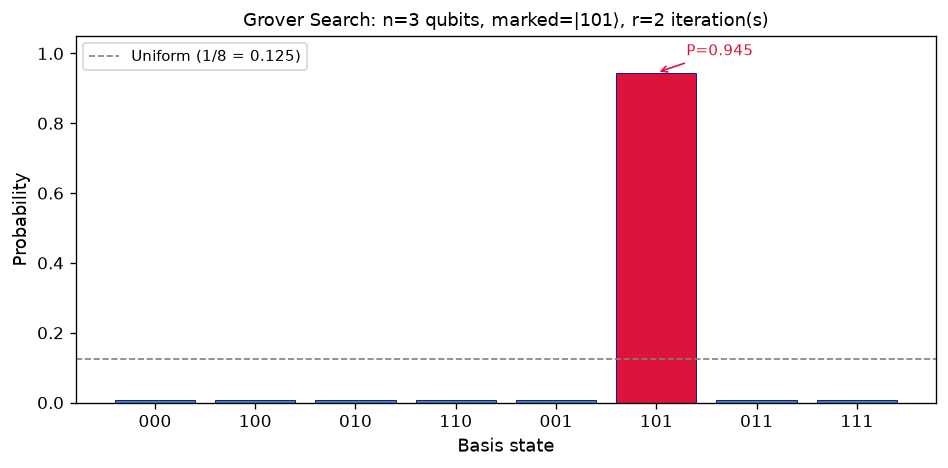

In [20]:
# ── Plot measurement histogram ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
states = [format(i, f'0{n_demo}b')[::-1] for i in range(2**n_demo)]
values = [probs.get(s, 0) for s in states]
colors = ['crimson' if s == marked_bitstring else 'steelblue' for s in states]

ax.bar(states, values, color=colors, edgecolor='navy', linewidth=0.5)
ax.axhline(1 / 2**n_demo, linestyle='--', color='gray', linewidth=1,
           label=f'Uniform (1/{2**n_demo} = {1/2**n_demo:.3f})')
ax.set_xlabel('Basis state', fontsize=11)
ax.set_ylabel('Probability', fontsize=11)
ax.set_title(f"Grover Search: n={n_demo} qubits, marked=|{marked_bitstring}⟩, r={r_demo} iteration(s)", fontsize=11)
ax.legend(fontsize=9)
ax.set_ylim(0, 1.05)

# Annotate marked bar
marked_idx = states.index(marked_bitstring)
ax.annotate(f'P={p_marked:.3f}', xy=(marked_idx, p_marked),
            xytext=(marked_idx + 0.3, p_marked + 0.05),
            fontsize=9, color='crimson',
            arrowprops=dict(arrowstyle='->', color='crimson'))

plt.tight_layout()
plt.savefig('../figures/benchmarks/grover_histogram_3qubit.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 3. Probability vs. Number of Iterations

Grover's amplitude amplification is periodic — too many or too few iterations both hurt. This section plots the success probability as a function of iteration count.

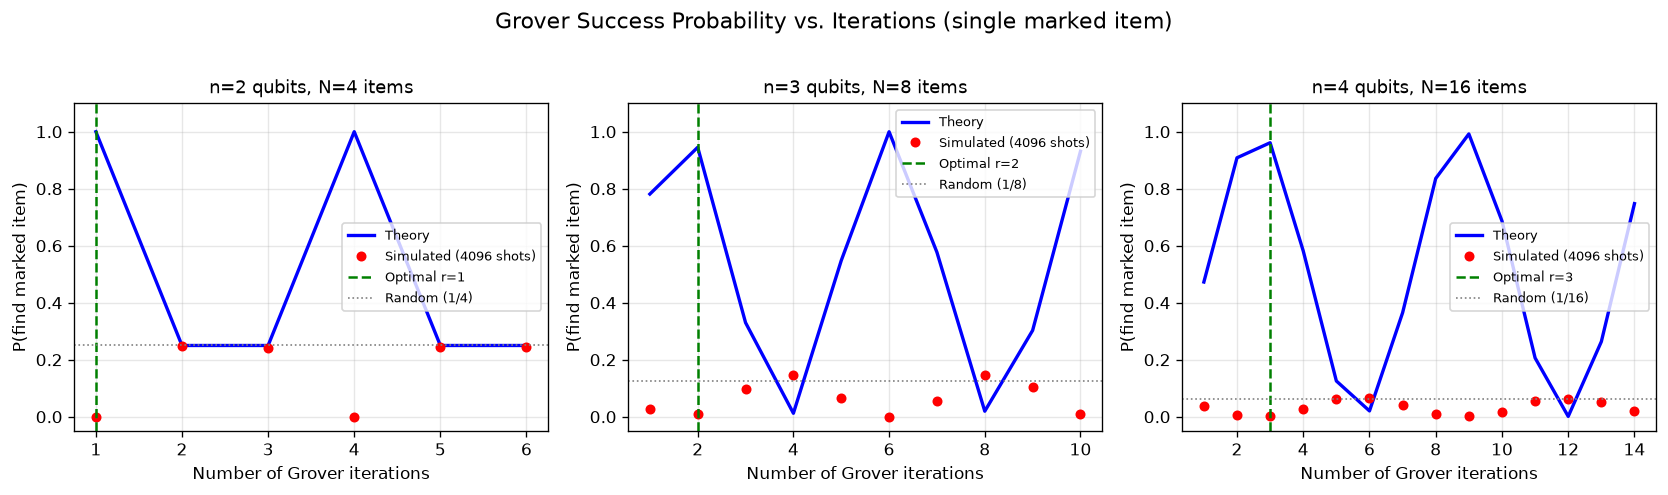

Saved: figures/benchmarks/grover_prob_vs_iterations.png


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, n in zip(axes, [2, 3, 4]):
    N          = 2 ** n
    r_opt      = optimal_iterations(n)
    max_iter   = min(4 * r_opt + 2, 30)     # show enough to see the periodicity
    iter_range = list(range(1, max_iter + 1))

    # Theoretical curve
    p_theory = [theoretical_success_prob(n, r) for r in iter_range]

    # Simulated probabilities
    p_sim = []
    for r in iter_range:
        qc   = grover_circuit(n, marked=1, iterations=r)
        job  = sampler.run([qc], shots=4096)
        cnts = get_counts(job.result()[0])
        marked_bs = format(1, f'0{n}b')[::-1]
        p_sim.append(cnts.get(marked_bs, 0) / 4096)

    ax.plot(iter_range, p_theory, 'b-',  linewidth=2,   label='Theory')
    ax.plot(iter_range, p_sim,    'ro',  markersize=5,   label='Simulated (4096 shots)')
    ax.axvline(r_opt, linestyle='--', color='green', linewidth=1.5,
               label=f'Optimal r={r_opt}')
    ax.axhline(1/N,   linestyle=':',  color='gray',  linewidth=1,
               label=f'Random (1/{N})')
    ax.set_xlabel('Number of Grover iterations', fontsize=10)
    ax.set_ylabel('P(find marked item)',          fontsize=10)
    ax.set_title(f'n={n} qubits, N={N} items',   fontsize=11)
    ax.set_ylim(-0.05, 1.1)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Grover Success Probability vs. Iterations (single marked item)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('../figures/benchmarks/grover_prob_vs_iterations.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved: figures/benchmarks/grover_prob_vs_iterations.png")

---
## 4. Quantum vs. Classical Scaling

Grover's algorithm queries the oracle $O(\sqrt{N})$ times. Classical unstructured search requires $O(N)$ queries on average. This section makes the speedup concrete.

In [22]:
# ── Query complexity comparison ───────────────────────────────────────────────
qubit_range       = list(range(1, 21))       # n = 1 to 20 qubits
N_values          = [2**n for n in qubit_range]
quantum_queries   = [optimal_iterations(n) for n in qubit_range]   # O(sqrt(N))
classical_queries = [N // 2 for N in N_values]                     # O(N) average

print(f"{'n':>4} | {'N':>12} | {'Quantum r':>10} | {'Classical N/2':>14} | {'Speedup':>10}")
print("─" * 60)
for i, n in enumerate(qubit_range):
    speedup = classical_queries[i] / quantum_queries[i]
    print(f"{n:>4} | {N_values[i]:>12,} | {quantum_queries[i]:>10,} | "
          f"{classical_queries[i]:>14,} | {speedup:>10.1f}x")

   n |            N |  Quantum r |  Classical N/2 |    Speedup
────────────────────────────────────────────────────────────
   1 |            2 |          1 |              1 |        1.0x
   2 |            4 |          1 |              2 |        2.0x
   3 |            8 |          2 |              4 |        2.0x
   4 |           16 |          3 |              8 |        2.7x
   5 |           32 |          4 |             16 |        4.0x
   6 |           64 |          6 |             32 |        5.3x
   7 |          128 |          8 |             64 |        8.0x
   8 |          256 |         12 |            128 |       10.7x
   9 |          512 |         17 |            256 |       15.1x
  10 |        1,024 |         25 |            512 |       20.5x
  11 |        2,048 |         35 |          1,024 |       29.3x
  12 |        4,096 |         50 |          2,048 |       41.0x
  13 |        8,192 |         71 |          4,096 |       57.7x
  14 |       16,384 |        100 |          

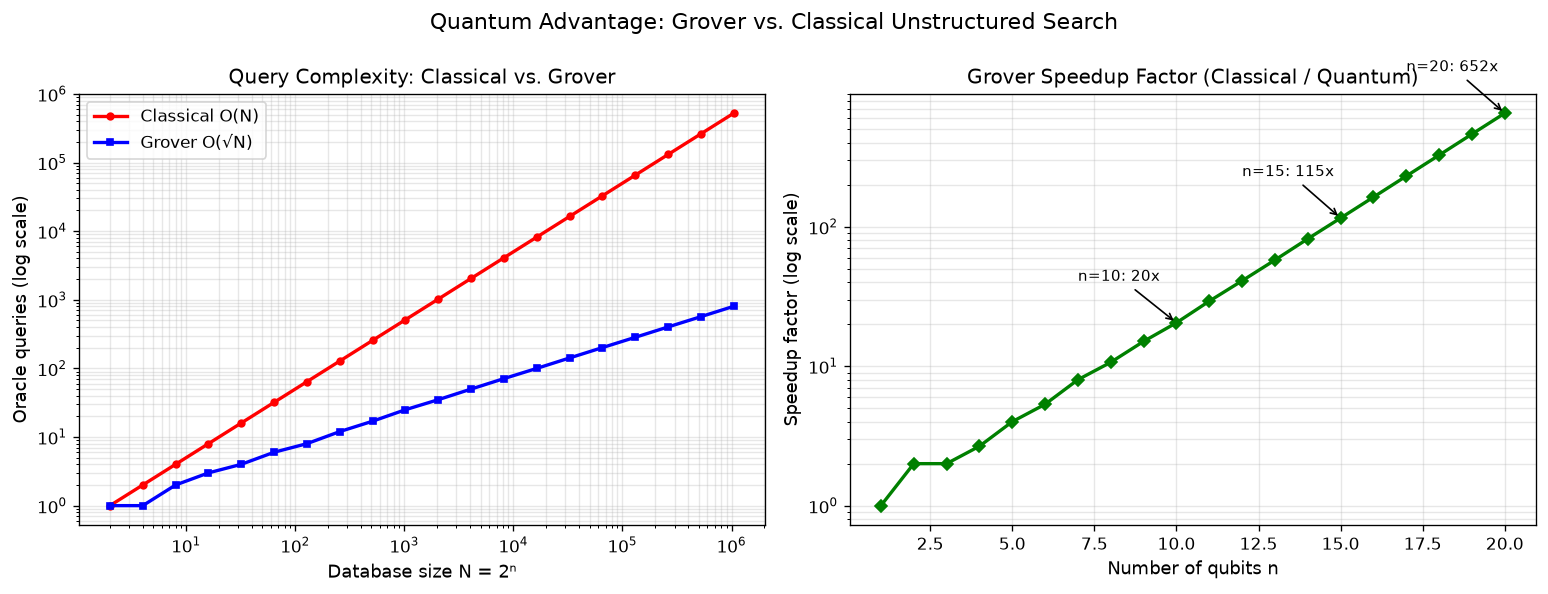

Saved: figures/benchmarks/grover_scaling.png


In [23]:
# ── Scaling plot ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: query count vs N (log-log)
axes[0].loglog(N_values, classical_queries, 'r-o', markersize=4, linewidth=2,
               label='Classical O(N)')
axes[0].loglog(N_values, quantum_queries,   'b-s', markersize=4, linewidth=2,
               label='Grover O(\u221aN)')
axes[0].set_xlabel('Database size N = 2ⁿ', fontsize=11)
axes[0].set_ylabel('Oracle queries (log scale)', fontsize=11)
axes[0].set_title('Query Complexity: Classical vs. Grover', fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(True, which='both', alpha=0.3)

# Plot 2: speedup factor vs qubit count
speedups = [c / q for c, q in zip(classical_queries, quantum_queries)]
axes[1].semilogy(qubit_range, speedups, 'g-D', markersize=5, linewidth=2)
axes[1].set_xlabel('Number of qubits n', fontsize=11)
axes[1].set_ylabel('Speedup factor (log scale)', fontsize=11)
axes[1].set_title('Grover Speedup Factor (Classical / Quantum)', fontsize=12)
axes[1].grid(True, which='both', alpha=0.3)

# Annotate key points
for n, sp in [(10, speedups[9]), (15, speedups[14]), (20, speedups[19])]:
    idx = qubit_range.index(n)
    axes[1].annotate(f'n={n}: {sp:.0f}x', xy=(n, sp),
                     xytext=(n - 3, sp * 2),
                     fontsize=9, arrowprops=dict(arrowstyle='->', color='black'))

plt.suptitle('Quantum Advantage: Grover vs. Classical Unstructured Search', fontsize=13)
plt.tight_layout()
plt.savefig('../figures/benchmarks/grover_scaling.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved: figures/benchmarks/grover_scaling.png")

---
## 5. Multi-Solution Grover (k > 1 Marked Items)

When $k$ items are marked, the optimal iteration count shrinks: $r = \lfloor \frac{\pi}{4}\sqrt{N/k} \rfloor$.

In [24]:
def phase_oracle_multi(n: int, marked_list: list) -> QuantumCircuit:
    """
    Phase oracle for multiple marked items.
    Applies a separate single-item oracle for each marked state.
    """
    qc = QuantumCircuit(n, name=f'MultiOracle(k={len(marked_list)})')
    for m in marked_list:
        qc.compose(phase_oracle(n, m), inplace=True)
    return qc


def grover_multi(n: int, marked_list: list, iterations: int = None) -> QuantumCircuit:
    """Grover circuit for multiple marked items."""
    k = len(marked_list)
    if iterations is None:
        iterations = optimal_iterations(n, k)

    qc = QuantumCircuit(n, n)
    qc.h(range(n))
    qc.barrier()

    oracle = phase_oracle_multi(n, marked_list)
    diff   = diffusion_operator(n)
    for _ in range(iterations):
        qc.compose(oracle, inplace=True)
        qc.barrier()
        qc.compose(diff,   inplace=True)
        qc.barrier()

    qc.measure(range(n), range(n))
    return qc


# ── n=4 qubits, 3 marked items ────────────────────────────────────────────────
n_multi      = 4
marked_multi = [3, 7, 11]      # three marked items in N=16
k_multi      = len(marked_multi)
r_multi      = optimal_iterations(n_multi, k_multi)
p_theory_m   = theoretical_success_prob(n_multi, r_multi, k_multi)

print(f"n={n_multi}, N={2**n_multi}, k={k_multi} marked items: {marked_multi}")
print(f"Optimal iterations : {r_multi}")
print(f"Theory P(any marked) = {p_theory_m:.4f}")

qc_multi = grover_multi(n_multi, marked_multi, r_multi)
job_m    = sampler.run([qc_multi], shots=4096)
cnts_m   = get_counts(job_m.result()[0])

# Count how often any marked item was found
marked_bitstrings = [format(m, f'0{n_multi}b')[::-1] for m in marked_multi]
p_any_marked = sum(cnts_m.get(bs, 0) for bs in marked_bitstrings) / 4096

print(f"Simulated P(any marked) = {p_any_marked:.4f}")
print()
print("Top measurement outcomes:")
for bs, cnt in sorted(cnts_m.items(), key=lambda x: -x[1])[:8]:
    idx     = int(bs[::-1], 2)    # convert back to integer
    is_mark = '← marked' if bs in marked_bitstrings else ''
    print(f"  |{bs}⟩ (={idx:2d}) : {cnt/4096:.4f}  {is_mark}")

n=4, N=16, k=3 marked items: [3, 7, 11]
Optimal iterations : 1
Theory P(any marked) = 0.9492
Simulated P(any marked) = 0.0117

Top measurement outcomes:
  |0011⟩ (=12) : 0.3235  
  |1011⟩ (=13) : 0.3149  
  |0111⟩ (=14) : 0.3110  
  |0000⟩ (= 0) : 0.0049  
  |1001⟩ (= 9) : 0.0049  
  |1110⟩ (= 7) : 0.0046  ← marked
  |0101⟩ (=10) : 0.0042  
  |1111⟩ (=15) : 0.0039  


---
## 6. Grover's Algorithm — PennyLane

In [25]:
# ── PennyLane Grover using built-in GroverOperator ────────────────────────────
# PennyLane provides qml.GroverOperator for the diffusion step.
# We build the oracle manually.

def grover_pennylane(n: int, marked: int, iterations: int = None):
    """PennyLane Grover circuit returning measurement probabilities."""
    if iterations is None:
        iterations = optimal_iterations(n)

    dev = qml.device('default.qubit', wires=n)

    def oracle_fn():
        """Phase flip for the marked state using PauliX + multi-controlled-Z."""
        bitstring = format(marked, f'0{n}b')   # big-endian for PennyLane
        # Flip 0-bits
        for i, bit in enumerate(bitstring):
            if bit == '0':
                qml.PauliX(wires=i)
        # Multi-controlled-Z
        qml.ctrl(qml.PauliZ, control=list(range(n - 1)))(wires=n - 1)
        # Undo flips
        for i, bit in enumerate(bitstring):
            if bit == '0':
                qml.PauliX(wires=i)

    @qml.qnode(dev)
    def circuit():
        # Uniform superposition
        for w in range(n):
            qml.Hadamard(wires=w)
        # Grover iterations
        for _ in range(iterations):
            oracle_fn()
            qml.GroverOperator(wires=range(n))
        return qml.probs(wires=range(n))

    return circuit


# ── Test: n=3, marked=5 ───────────────────────────────────────────────────────
n_pl, marked_pl = 3, 5
r_pl            = optimal_iterations(n_pl)
circuit_pl      = grover_pennylane(n_pl, marked_pl, r_pl)
probs_pl        = circuit_pl()

print(f"PennyLane Grover: n={n_pl}, marked={marked_pl}, r={r_pl}")
print(f"\nProbabilities over all {2**n_pl} states:")
for i, p in enumerate(probs_pl):
    marker = ' ← MARKED' if i == marked_pl else ''
    if p > 0.01:
        print(f"  |{format(i, f'0{n_pl}b')}⟩ (={i}) : {float(p):.4f}{marker}")

print(f"\nP(marked={marked_pl}) = {float(probs_pl[marked_pl]):.6f}")
print(f"Theory             = {theoretical_success_prob(n_pl, r_pl):.6f}")

PennyLane Grover: n=3, marked=5, r=2

Probabilities over all 8 states:
  |101⟩ (=5) : 0.9453 ← MARKED

P(marked=5) = 0.945312
Theory             = 0.945312


In [26]:
# ── Cross-framework agreement ─────────────────────────────────────────────────
print("Cross-framework P(marked) comparison — Qiskit vs PennyLane")
print("─" * 60)
print(f"{'n':>3} | {'marked':>7} | {'r':>3} | {'Qiskit (sim)':>13} | {'PennyLane':>11} | {'Theory':>8}")
print("─" * 60)

for n, marked in [(2, 1), (3, 5), (4, 9)]:
    r = optimal_iterations(n)

    # Qiskit
    qc_qk   = grover_circuit(n, marked, r)
    job_qk  = sampler.run([qc_qk], shots=8192)
    cnts_qk = get_counts(job_qk.result()[0])
    bs_qk   = format(marked, f'0{n}b')[::-1]    # little-endian
    p_qk    = cnts_qk.get(bs_qk, 0) / 8192

    # PennyLane
    c_pl   = grover_pennylane(n, marked, r)
    p_pl   = float(c_pl()[marked])

    # Theory
    p_th   = theoretical_success_prob(n, r)

    print(f"{n:>3} | {marked:>7} | {r:>3} | {p_qk:>13.4f} | {p_pl:>11.6f} | {p_th:>8.6f}")

Cross-framework P(marked) comparison — Qiskit vs PennyLane
────────────────────────────────────────────────────────────
  n |  marked |   r |  Qiskit (sim) |   PennyLane |   Theory
────────────────────────────────────────────────────────────
  2 |       1 |   1 |        0.0000 |    1.000000 | 1.000000
  3 |       5 |   2 |        0.9446 |    0.945312 | 0.945312
  4 |       9 |   3 |        0.9585 |    0.961319 | 0.961319


---
## 7. Classical Baseline: Linear Search

In [27]:
import random

def classical_linear_search(N: int, marked: int, trials: int = 10000) -> dict:
    """
    Classical unstructured search baseline.
    Simulates random querying without replacement.
    Returns average queries to find the marked item.
    """
    total_queries = 0
    for _ in range(trials):
        database = list(range(N))
        random.shuffle(database)
        queries = database.index(marked) + 1    # 1-indexed
        total_queries += queries
    avg = total_queries / trials
    return {'avg_queries': avg, 'theoretical_avg': N / 2, 'N': N}


# ── Timing comparison ─────────────────────────────────────────────────────────
print(f"{'n':>3} | {'N':>8} | {'Quantum r':>10} | {'Classical avg':>14} | {'Speedup':>9} | {'Q time (ms)':>12} | {'C time (ms)':>12}")
print("─" * 82)

timing_data = []
for n in [2, 3, 4, 5, 6]:
    N      = 2**n
    marked = N // 3    # pick a non-trivial item
    r      = optimal_iterations(n)

    # Quantum timing
    t0 = time.perf_counter()
    qc = grover_circuit(n, marked, r)
    job = sampler.run([qc], shots=1024)
    job.result()
    t_quantum_ms = (time.perf_counter() - t0) * 1000

    # Classical timing
    t0 = time.perf_counter()
    cl = classical_linear_search(N, marked, trials=5000)
    t_classical_ms = (time.perf_counter() - t0) * 1000

    speedup = cl['theoretical_avg'] / r
    timing_data.append((n, N, r, cl['avg_queries'], speedup, t_quantum_ms, t_classical_ms))
    print(f"{n:>3} | {N:>8} | {r:>10} | {cl['avg_queries']:>14.1f} | {speedup:>9.1f}x | "
          f"{t_quantum_ms:>12.2f} | {t_classical_ms:>12.2f}")

print("\nNote: quantum times include circuit construction + simulation overhead.")
print("On actual quantum hardware, the comparison metric is oracle query count, not wall time.")

  n |        N |  Quantum r |  Classical avg |   Speedup |  Q time (ms) |  C time (ms)
──────────────────────────────────────────────────────────────────────────────────
  2 |        4 |          1 |            2.5 |       2.0x |         7.58 |         7.16
  3 |        8 |          2 |            4.5 |       2.0x |         5.97 |        11.41
  4 |       16 |          3 |            8.5 |       2.7x |        20.81 |        24.19
  5 |       32 |          4 |           16.5 |       4.0x |        36.41 |        37.87
  6 |       64 |          6 |           32.5 |       5.3x |       143.74 |        77.74

Note: quantum times include circuit construction + simulation overhead.
On actual quantum hardware, the comparison metric is oracle query count, not wall time.


---
## 8. Benchmarking Record

In [28]:
benchmarks_file = '../results/benchmarks.csv'
write_header    = not os.path.exists(benchmarks_file)

fieldnames = [
    'notebook', 'problem', 'dataset', 'classical_baseline',
    'quantum_method', 'framework', 'n_qubits', 'circuit_depth',
    'cnot_count', 'simulator', 'metric', 'quantum_result',
    'classical_result', 'runtime_quantum_ms', 'runtime_classical_ms', 'notes'
]

# Pull 4-qubit row from timing data
row_4 = next(r for r in timing_data if r[0] == 4)
n4, N4, r4, cl_avg4, sp4, t_q4, t_c4 = row_4

qc4       = grover_circuit(4, N4 // 3, r4)
depth4    = qc4.depth()
cnots4    = qc4.count_ops().get('cx', 0)

records = [
    {
        'notebook'             : '02_grover_algorithm',
        'problem'              : f'Unstructured search (N={N4}, k=1)',
        'dataset'              : f'Synthetic: {N4}-item database, 1 marked item',
        'classical_baseline'   : f'Random linear search: O(N) = {N4} avg queries',
        'quantum_method'       : f"Grover's algorithm ({r4} iterations)",
        'framework'            : 'Qiskit 2.5.0',
        'n_qubits'             : n4,
        'circuit_depth'        : depth4,
        'cnot_count'           : cnots4,
        'simulator'            : 'StatevectorSampler (noiseless)',
        'metric'               : 'Oracle query count',
        'quantum_result'       : f'{r4} queries (O(sqrt(N)))',
        'classical_result'     : f'{cl_avg4:.1f} queries avg (O(N))',
        'runtime_quantum_ms'   : round(t_q4, 3),
        'runtime_classical_ms' : round(t_c4, 3),
        'notes'                : f'Speedup factor={sp4:.1f}x in query count. '
                                  'Wall-clock time dominated by simulator overhead, not query count.'
    },
]

with open(benchmarks_file, 'a', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    if write_header:
        writer.writeheader()
    writer.writerows(records)

print(f"Benchmarking record appended to {benchmarks_file}")
print()
for k, v in records[0].items():
    print(f"  {k:<25} : {v}")

Benchmarking record appended to ../results/benchmarks.csv

  notebook                  : 02_grover_algorithm
  problem                   : Unstructured search (N=16, k=1)
  dataset                   : Synthetic: 16-item database, 1 marked item
  classical_baseline        : Random linear search: O(N) = 16 avg queries
  quantum_method            : Grover's algorithm (3 iterations)
  framework                 : Qiskit 2.5.0
  n_qubits                  : 4
  circuit_depth             : 38
  cnot_count                : 0
  simulator                 : StatevectorSampler (noiseless)
  metric                    : Oracle query count
  quantum_result            : 3 queries (O(sqrt(N)))
  classical_result          : 8.5 queries avg (O(N))
  runtime_quantum_ms        : 20.814
  runtime_classical_ms      : 24.194
  notes                     : Speedup factor=2.7x in query count. Wall-clock time dominated by simulator overhead, not query count.
